In [1]:
import os, glob, time, math, random, platform, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
set_seed()

Q1 a)

In [2]:
A_nb = np.array([-1,+1,0,0])
B_nb = np.array([-1,+1,-1,+1])
w, c = 0.7, -1.3
for name, nb in [('A', A_nb), ('B', B_nb)]:
    print(name, 'n_v =', len(nb), 'S_v =', nb.sum(), 'steady =', (nb == 0).sum(), '-> aggregated message =', w * nb.sum() + c * len(nb))

A n_v = 4 S_v = 0 steady = 2 -> aggregated message = -5.2
B n_v = 4 S_v = 0 steady = 0 -> aggregated message = -5.2


Q1 b)

In [3]:
K = 8
base = K + 1
phi = {-1: 1, 0: base, +1: base ** 2}

def encode(neighbours):
    return sum(phi[x] for x in neighbours)

def decode(s):
    return s % base, (s // base) % base, s // base ** 2

seen = {}
for a in range(K + 1):
    for b in range(K + 1):
        for c in range(K + 1):
            if 1 <= a + b + c <= K:
                s = encode([-1] * a + [0] * b + [1] * c)
                assert decode(s) == (a, b, c)
                assert s not in seen
                seen[s] = (a, b, c)
print('Checked', len(seen), 'count triples for K=8: all distinct and all decoded correctly')

phi_ns = {-1: 1, 0: 0, +1: 1}
nb = [-1, 0, 1, 1, 0]
print('non-steady count:', sum(phi_ns[x] for x in nb), '(expected 3)')

Checked 164 count triples for K=8: all distinct and all decoded correctly
non-steady count: 3 (expected 3)


Q1 c)

In [4]:
onehot = {-1: np.array([1, 0, 0]), 0: np.array([0, 1, 0]), 1: np.array([0, 0, 1])}
def agg(nb):
    M = np.stack([onehot[x] for x in nb])
    return M.sum(0), M.mean(0).round(3), M.max(0)

for nb in [[0], [0, 0], [-1, 0], [-1, -1, 0]]:
    s, m, mx = agg(nb)
    print(f'{str(nb):12s} sum={s} mean={m} max={mx}')

[0]          sum=[0 1 0] mean=[0. 1. 0.] max=[0 1 0]
[0, 0]       sum=[0 2 0] mean=[0. 1. 0.] max=[0 1 0]
[-1, 0]      sum=[1 1 0] mean=[0.5 0.5 0. ] max=[1 1 0]
[-1, -1, 0]  sum=[2 1 0] mean=[0.667 0.333 0.   ] max=[1 1 0]


In [5]:
N_RING = 40
x0 = np.zeros(N_RING); x0[20] = 1
target = np.roll(x0, -1)

design = np.stack([x0, np.roll(x0, 1) + np.roll(x0, -1)], axis=1)
(a_fit, b_fit), *_ = np.linalg.lstsq(design, target, rcond=None)
print('a =', round(a_fit, 4), ' b =', round(b_fit, 4))
print('squared error =', ((design @ [a_fit, b_fit] - target) ** 2).sum())

a = 0.0  b = 0.5
squared error = 0.5


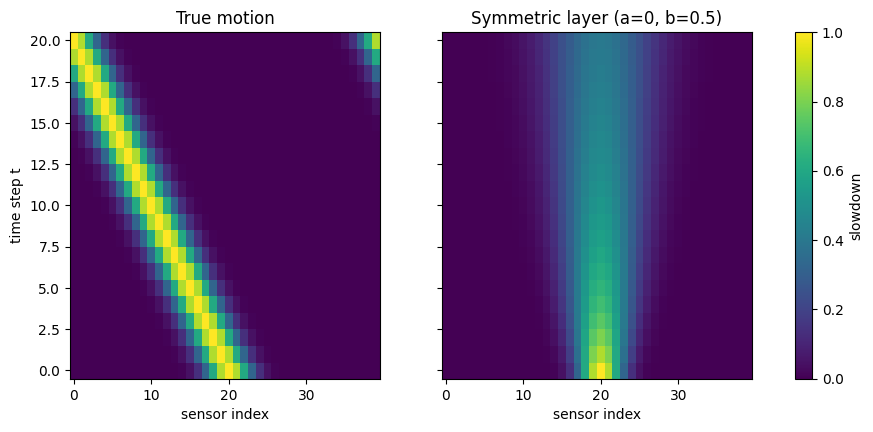

peak value after 20 steps  true: 1.0  learned: 0.405


In [6]:
def sym_layer(x, a=a_fit, b=b_fit):
    return a * x + b * (np.roll(x, 1) + np.roll(x, -1))

idx = np.arange(N_RING)
bump = np.exp(-(idx - 20) ** 2 / 8)
pred_seq, true_seq = [bump], [bump]
for t in range(20):
    pred_seq.append(sym_layer(pred_seq[-1]))
    true_seq.append(np.roll(true_seq[-1], -1))
pred_seq, true_seq = np.array(pred_seq), np.array(true_seq)

vmin, vmax = 0, 1
fig, axs = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, data, title in zip(axs, [true_seq, pred_seq], ['True motion', 'Symmetric layer (a=0, b=0.5)']):
    im = ax.imshow(data, aspect='auto', origin='lower', vmin=vmin, vmax=vmax, cmap='viridis')
    ax.set_title(title); ax.set_xlabel('sensor index')
axs[0].set_ylabel('time step t')
fig.colorbar(im, ax=axs, label='slowdown')
plt.show()
print('peak value after 20 steps  true:', true_seq[-1].max().round(3), ' learned:', pred_seq[-1].max().round(3))

In [7]:
rng = np.random.default_rng(0)
x = rng.normal(size=N_RING)
pred_b = 0 * x + 0 * np.roll(x, 1) + 1 * np.roll(x, -1)
print('(b) exact:', np.allclose(pred_b, np.roll(x, -1)))

def circ_corr(x, kernel):
    return kernel[0] * np.roll(x, 1) + kernel[1] * x + kernel[2] * np.roll(x, -1)
print('(b) conv kernel [0,0,1]:', np.allclose(circ_corr(x, [0, 0, 1]), np.roll(x, -1)))

a, b, c = 0, 1, -1
def predict_c(x_now, x_prev):
    return a * x_now + b * (np.roll(x_now, 1) + np.roll(x_now, -1)) + c * x_prev

prev = rng.normal(size=N_RING)
for name, shift in [('backward', -1), ('forward', +1)]:
    now = np.roll(prev, shift); nxt = np.roll(now, shift)
    print(f'(c) {name}: exact =', np.allclose(predict_c(now, prev), nxt))

(b) exact: True
(b) conv kernel [0,0,1]: True
(c) backward: exact = True
(c) forward: exact = True


In [8]:
import torch, torch.nn as nn, torch.nn.functional as F
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)

CFG = dict(
    hist=8,
    horizon=4,
    hidden=32,
    emb_dim=10,
    topk=20,
    epochs=30,
    batch=64,
    lr=1e-3,
    patience=6,
    seed=SEED,
)
ZERO_IS_MISSING = False

device: cuda


In [9]:
import kagglehub
DATA_DIR = kagglehub.dataset_download("liuxu77/largest")
print(DATA_DIR)

Using Colab cache for faster access to the 'largest' dataset.
/kaggle/input/largest


In [10]:
def find(pattern):
    hits = sorted(glob.glob(os.path.join(DATA_DIR, '**', pattern), recursive=True))
    return hits
for p in find('*'):
    if os.path.isfile(p): print(os.path.relpath(p, DATA_DIR), f'{os.path.getsize(p)/1e6:.0f} MB')

ca_his_raw_2017.h5 7233 MB
ca_his_raw_2018.h5 7233 MB
ca_his_raw_2019.h5 7233 MB
ca_his_raw_2020.h5 7253 MB
ca_his_raw_2021.h5 7233 MB
ca_meta.csv 1 MB
ca_rn_adj.npy 592 MB


In [11]:
import h5py, gc

meta = pd.read_csv(find('ca_meta.csv')[0])
print(meta.columns.tolist())
sd_meta = meta[meta['District'] == 11].copy()
print('San Diego sensors:', len(sd_meta))
assert len(sd_meta) == 716, 'Check the meta columns: pick the rows that belong to San Diego'
sd_ids = sd_meta['ID'].astype(str).tolist()
pos_in_sd = {s: i for i, s in enumerate(sd_ids)}

def _txt(a):
    return [x.decode() if isinstance(x, bytes) else str(x) for x in a]

def read_sd_5min(path, chunk_rows=5000):
    with h5py.File(path, 'r') as f:
        g = f[list(f.keys())[0]]
        print('  hdf5 group contents:', list(g.keys()))
        if 'block0_values' in g:
            idx = g['axis1'][:]
            idx = pd.to_datetime(_txt(idx)) if idx.dtype.kind in 'SO' else pd.to_datetime(idx)
            out = np.full((len(idx), len(sd_ids)), np.nan, dtype='float32')
            b = 0
            while f'block{b}_values' in g:
                items = _txt(g[f'block{b}_items'][:])
                src_cols = [i for i, c in enumerate(items) if c in pos_in_sd]
                dst_cols = [pos_in_sd[items[i]] for i in src_cols]
                vals = g[f'block{b}_values']
                rows_first = (vals.shape[0] == len(idx))
                for s in range(0, len(idx), chunk_rows):
                    e = min(s + chunk_rows, len(idx))
                    chunk = vals[s:e, :] if rows_first else vals[:, s:e].T
                    out[s:e, dst_cols] = chunk[:, src_cols]
                b += 1
            return pd.DataFrame(out, index=idx, columns=sd_ids)
    parts, s = [], 0
    while True:
        part = pd.read_hdf(path, start=s, stop=s + chunk_rows, columns=sd_ids)
        if len(part) == 0: break
        parts.append(part.astype('float32')); s += chunk_rows
    df = pd.concat(parts); df.columns = df.columns.astype(str)
    df.index = pd.to_datetime(df.index)
    return df[sd_ids]

def load_year_15min(year):
    cands = sorted(find(f'*his*{year}*.h5'), key=lambda p: ('sd' not in os.path.basename(p).lower(), p))
    path = cands[0]
    print('reading', path)
    df = read_sd_5min(path)
    df = df[(df.index >= f'{year}-01-01') & (df.index < f'{year+1}-01-01')]
    nan_frac, zero_frac = float(df.isna().values.mean()), float((df == 0).values.mean())
    if ZERO_IS_MISSING:
        df = df.replace(0, np.nan)
    flow = df.resample('15min').mean() * 3
    print(f'  {year}: 5-min table {df.shape}, NaN {nan_frac:.4f}, zeros {zero_frac:.4f} -> 15-min table {flow.shape}')
    del df; gc.collect()
    return flow.astype('float32')

flow15 = pd.concat([load_year_15min(2020), load_year_15min(2021)])
print('15-min table:', flow15.shape)

['ID', 'Lat', 'Lng', 'District', 'County', 'Fwy', 'Lanes', 'Type', 'Direction', 'ID2']
San Diego sensors: 716
reading /kaggle/input/largest/ca_his_raw_2020.h5
  hdf5 group contents: ['axis0', 'axis1', 'block0_items', 'block0_values']
  2020: 5-min table (105408, 716), NaN 0.0410, zeros 0.0028 -> 15-min table (35136, 716)
reading /kaggle/input/largest/ca_his_raw_2021.h5
  hdf5 group contents: ['axis0', 'axis1', 'block0_items', 'block0_values']
  2021: 5-min table (105120, 716), NaN 0.0603, zeros 0.0025 -> 15-min table (35040, 716)
15-min table: (70176, 716)


In [12]:
missing_mask = flow15.isna()
print('missing fraction at 15-min level:', float(missing_mask.values.mean()))

flow15 = flow15.interpolate(limit=8, limit_direction='both')

train_mean_per_sensor = flow15[flow15.index < '2021-01-01'].mean()
global_train_mean = flow15[flow15.index < '2021-01-01'].stack().mean()

flow15 = flow15.fillna(train_mean_per_sensor)
flow15 = flow15.fillna(global_train_mean)
flow15 = flow15.fillna(0.0)

observed = ~missing_mask.values

adj_path = (find('sd_rn_adj.npy') or find('ca_rn_adj.npy'))[0]
adj_full = np.load(adj_path, mmap_mode="r")
if adj_full.shape[0] == 716:
    A = np.array(adj_full, dtype=np.float32)
else:
    rows = sd_meta.index.values
    A = np.array(adj_full[rows][:, rows], dtype=np.float32)
del adj_full; gc.collect()
print('adjacency:', A.shape, 'from', os.path.basename(adj_path))
print('Are there any NaNs remaining in flow15?', flow15.isna().any().any())

missing fraction at 15-min level: 0.050591414053603775
adjacency: (716, 716) from ca_rn_adj.npy
Are there any NaNs remaining in flow15? False


(70176, 716) 2020-01-01 00:00:00 -> 2021-12-31 23:45:00


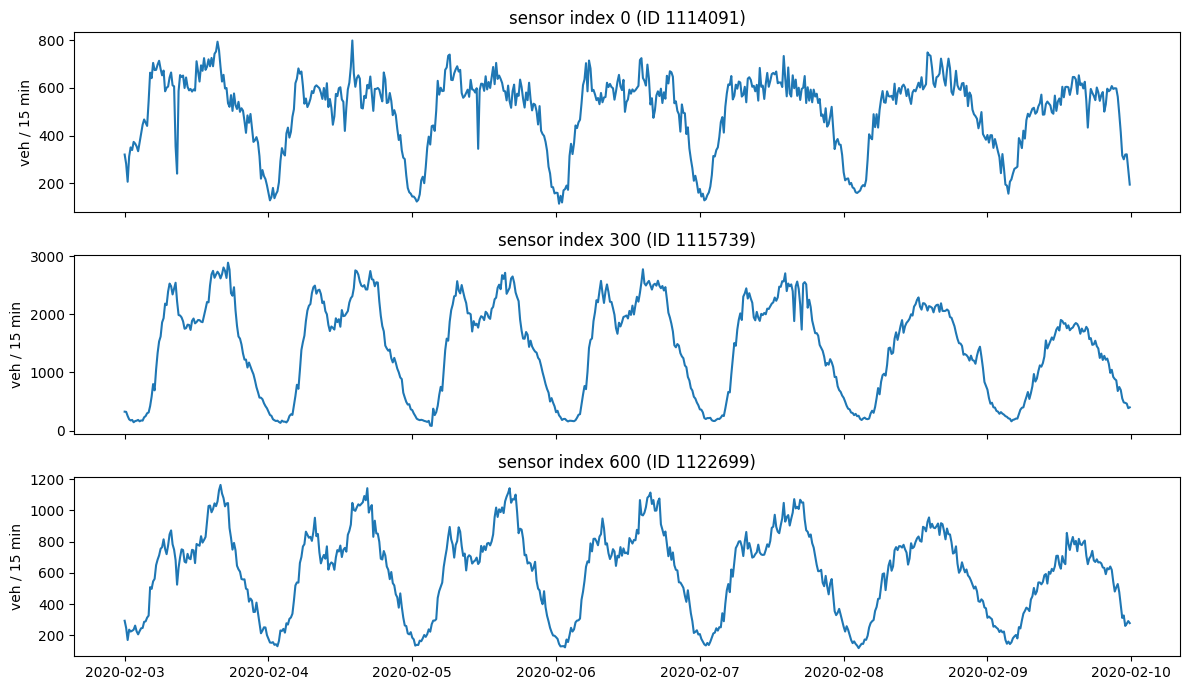

In [13]:
print(flow15.shape, flow15.index[0], '->', flow15.index[-1])
assert flow15.shape[1] == 716 and A.shape == (716, 716)
assert list(flow15.columns) == sd_meta['ID'].astype(str).tolist()

week = flow15.loc['2020-02-03':'2020-02-09 23:45']
fig, axs = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
for ax, s in zip(axs, [0, 300, 600]):
    ax.plot(week.index, week.iloc[:, s]); ax.set_ylabel('veh / 15 min')
    ax.set_title(f'sensor index {s} (ID {week.columns[s]})')
plt.tight_layout()
plt.show()

nodes: 716 | non-zero entries: 18035 | excluding self-loops: 17319
value range: min 0.0 max 1.0 | distinct values: 5208
symmetric?   False | asymmetric entries: 21022
neighbours per sensor: mean 24.19 min 0 max 70


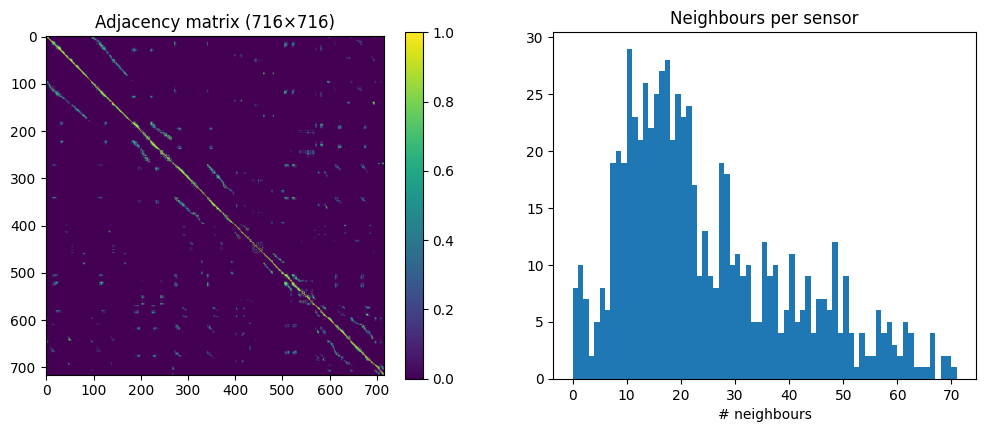

In [14]:
nnz_total = int((A != 0).sum())
nnz_offdiag = int((A != 0).sum() - (np.diag(A) != 0).sum())
print('nodes:', A.shape[0], '| non-zero entries:', nnz_total, '| excluding self-loops:', nnz_offdiag)
print('value range: min', A.min(), 'max', A.max(), '| distinct values:', len(np.unique(A)))
print('symmetric?  ', np.allclose(A, A.T), '| asymmetric entries:', int((A != A.T).sum()))

neighbours = (A != 0).sum(1) - (np.diag(A) != 0)
print('neighbours per sensor: mean', neighbours.mean().round(2), 'min', neighbours.min(), 'max', neighbours.max())

fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
im = axs[0].imshow(A, cmap='viridis')
axs[0].set_title('Adjacency matrix (716×716)')
plt.colorbar(im, ax=axs[0])
axs[1].hist(neighbours, bins=range(0, int(neighbours.max()) + 2)); axs[1].set_title('Neighbours per sensor')
axs[1].set_xlabel('# neighbours')
plt.show()

sensor 100: 11 one-hop neighbours [2, 3, 4, 5, 6, 97, 98, 99, 101, 102, 103]
36 nodes within two hops


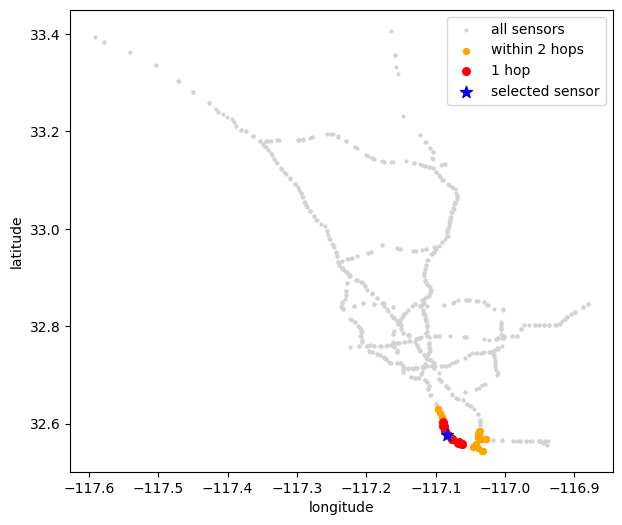

In [15]:
Bin = (A != 0).astype(np.int32)
np.fill_diagonal(Bin, 0)
i = 100
one_hop = np.where(Bin[i] > 0)[0]
two_hop = np.where(((Bin @ Bin + Bin)[i] > 0))[0]
two_hop = two_hop[two_hop != i]
print(f'sensor {i}: {len(one_hop)} one-hop neighbours {one_hop.tolist()}')
print(f'{len(two_hop)} nodes within two hops')

lat, lng = sd_meta['Lat'].values, sd_meta['Lng'].values
plt.figure(figsize=(7, 6))
plt.scatter(lng, lat, s=4, c='lightgrey', label='all sensors')
plt.scatter(lng[two_hop], lat[two_hop], s=18, c='orange', label='within 2 hops')
plt.scatter(lng[one_hop], lat[one_hop], s=30, c='red', label='1 hop')
plt.scatter(lng[i], lat[i], s=80, c='blue', marker='*', label='selected sensor')
plt.legend()
plt.xlabel('longitude')
plt.ylabel('latitude')
plt.show()

In [16]:
HIST, HOR = CFG['hist'], CFG['horizon']
times = flow15.index
split_masks = {
    'train': times < '2021-01-01',
    'val':   (times >= '2021-01-01') & (times < '2021-04-01'),
    'test':  times >= '2021-04-01',
}
data_np = flow15.values.astype(np.float32)

tr = split_masks['train']
mu = data_np[tr][observed[tr]].mean()
sd = data_np[tr][observed[tr]].std()
print(f'train mean {mu:.2f}  std {sd:.2f}  (vehicles / 15 min)')

class Split:
    def __init__(self, name):
        m = split_masks[name]
        self.times = times[m]
        self.data = torch.tensor((data_np[m] - mu) / sd, device=device)
        self.obs = torch.tensor(observed[m], device=device).float()
        self.n = len(self.data) - (HIST + HOR) + 1
        self.offsets = torch.arange(HIST + HOR, device=device)
    def batches(self, batch_size, shuffle):
        order = torch.randperm(self.n, device=device) if shuffle else torch.arange(self.n, device=device)
        for k in range(0, self.n, batch_size):
            start = order[k:k + batch_size]
            win = start[:, None] + self.offsets
            x = self.data[win[:, :HIST]]
            y = self.data[win[:, HIST:]]
            m = self.obs[win[:, HIST:]]
            yield x, y, m

splits = {k: Split(k) for k in ['train', 'val', 'test']}
print({k: v.n for k, v in splits.items()}, 'windows')

train mean 607.39  std 483.77  (vehicles / 15 min)
{'train': 35125, 'val': 8629, 'test': 26389} windows


In [17]:
def normalise_fixed(A_raw):
    A_tilde = A_raw.astype(np.float32).copy()
    A_tilde[A_tilde < 0] = 0
    np.fill_diagonal(A_tilde, 0)
    A_tilde = A_tilde + np.eye(len(A_tilde), dtype=np.float32)
    return A_tilde / A_tilde.sum(1, keepdims=True)

A_hat_fixed = torch.tensor(normalise_fixed(A), device=device)
print('row sums of A_hat:', A_hat_fixed.sum(1)[:5])

row sums of A_hat: tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000], device='cuda:0')


In [20]:
class STGNN(nn.Module):
    def __init__(self, mode, A_hat=None, n_nodes=716, d=32, hist=8, horizon=4, emb_dim=10, topk=20):
        super().__init__()
        assert mode in ['none', 'fixed', 'adaptive', 'hybrid']
        self.mode, self.topk = mode, topk

        self.tconv = nn.Sequential(nn.Conv1d(1, d, kernel_size=3), nn.ReLU(),
                                   nn.Conv1d(d, d, kernel_size=3), nn.ReLU())
        self.tproj = nn.Linear(d * (hist - 4), d)

        self.Wg = nn.Linear(d, d)

        self.head = nn.Sequential(nn.Linear(d, d), nn.ReLU(), nn.Linear(d, horizon))

        if mode in ['fixed', 'hybrid']:
            self.register_buffer('A_fixed', A_hat)
        if mode in ['adaptive', 'hybrid']:
            self.E1 = nn.Parameter(torch.randn(n_nodes, emb_dim))
            self.E2 = nn.Parameter(torch.randn(n_nodes, emb_dim))
        if mode == 'hybrid':
            self.alpha_raw = nn.Parameter(torch.zeros(1))

    def adaptive_adj(self):
        scores = F.relu(self.E1 @ self.E2.T)
        if self.topk is not None:
            top_vals, top_idx = scores.topk(self.topk, dim=1)
            keep = torch.zeros_like(scores, dtype=torch.bool).scatter_(1, top_idx, True)
            scores = scores.masked_fill(~keep, float('-inf'))
        return torch.softmax(scores, dim=1)

    def get_adj(self):
        if self.mode == 'fixed':
            return self.A_fixed
        if self.mode == 'adaptive':
            return self.adaptive_adj()
        if self.mode == 'hybrid':
            alpha = torch.sigmoid(self.alpha_raw)
            return alpha * self.A_fixed + (1 - alpha) * self.adaptive_adj()
        return None

    def forward(self, x):
        B, T, N = x.shape
        z = x.permute(0, 2, 1).reshape(B * N, 1, T)
        z = self.tconv(z).reshape(B * N, -1)
        z = F.relu(self.tproj(z)).reshape(B, N, -1)
        A_hat = self.get_adj()
        if A_hat is not None:
            z = torch.einsum('nm,bmd->bnd', A_hat, z)
        h = F.relu(self.Wg(z))
        y = self.head(h)
        return y.permute(0, 2, 1)

m = STGNN('hybrid', A_hat_fixed, d=CFG['hidden']).to(device)
print('parameters:', sum(p.numel() for p in m.parameters()))
xb, yb, mb = next(splits['val'].batches(4, False))
print('input', tuple(xb.shape), '-> output', tuple(m(xb).shape), '(should be B × 4 × 716)')

parameters: 23925
input (4, 8, 716) -> output (4, 4, 716) (should be B × 4 × 716)


In [22]:
def masked_mae(pred, y, m):
    return (torch.abs(pred - y) * m).sum() / m.sum().clamp(min=1)

@torch.no_grad()
def evaluate(model, split, keep_h1=False):
    model.eval()
    abs_sum = torch.zeros(HOR, device=device); sq_sum = torch.zeros(HOR, device=device); cnt = torch.zeros(HOR, device=device)
    h1 = []
    for x, y, m in split.batches(256, shuffle=False):
        pred = model(x) * sd + mu
        true = y * sd + mu
        err = (pred - true) * m
        abs_sum += err.abs().sum(dim=(0, 2)); sq_sum += (err ** 2).sum(dim=(0, 2)); cnt += m.sum(dim=(0, 2))
        if keep_h1: h1.append(pred[:, 0].cpu())
    out = dict(MAE=(abs_sum.sum() / cnt.sum()).item(),
               RMSE=torch.sqrt(sq_sum.sum() / cnt.sum()).item(),
               MAE_by_horizon=(abs_sum / cnt).cpu().numpy().round(2))
    if keep_h1: out['pred_h1'] = torch.cat(h1).numpy()
    return out

def train_model(mode):
    set_seed(CFG['seed']); torch.manual_seed(CFG['seed'])
    model = STGNN(mode, A_hat_fixed, d=CFG['hidden'], emb_dim=CFG['emb_dim'], topk=CFG['topk']).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=CFG['lr'])
    best_val, best_state, bad = float('inf'), None, 0
    if device.type == 'cuda': torch.cuda.synchronize()
    t0 = time.time()
    for epoch in range(CFG['epochs']):
        model.train(); losses = []
        for x, y, m in splits['train'].batches(CFG['batch'], shuffle=True):
            opt.zero_grad()
            loss = masked_mae(model(x), y, m)
            loss.backward(); opt.step(); losses.append(loss.item())
        val = evaluate(model, splits['val'])
        print(f'[{mode:8s}] epoch {epoch+1:02d} train loss {np.mean(losses)*sd:.2f} | val MAE {val['MAE']:.2f} RMSE {val['RMSE']:.2f}')
        if val['MAE'] < best_val - 1e-4:
            best_val, bad = val['MAE'], 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= CFG['patience']: print('early stop'); break
    if device.type == 'cuda': torch.cuda.synchronize()
    train_time = time.time() - t0
    model.load_state_dict(best_state)
    val = evaluate(model, splits['val']); test = evaluate(model, splits['test'], keep_h1=True)
    return model, dict(mode=mode, val=val, test=test, time=train_time)

In [23]:
runs, models = {}, {}
for mode in ['none', 'fixed', 'adaptive', 'hybrid']:
    try:
        models[mode], runs[mode] = train_model(mode)
    except Exception as e:
        print(f'Error training {mode}: {e}')
if 'hybrid' in models and models['hybrid'] is not None:
    try:
        print('learned alpha (hybrid):', torch.sigmoid(models['hybrid'].alpha_raw).item())
    except Exception: pass

[none    ] epoch 01 train loss 90.85 | val MAE 62.82 RMSE 99.34
[none    ] epoch 02 train loss 59.40 | val MAE 60.20 RMSE 97.09
[none    ] epoch 03 train loss 58.72 | val MAE 60.04 RMSE 96.65
[none    ] epoch 04 train loss 58.60 | val MAE 61.18 RMSE 97.57
[none    ] epoch 05 train loss 58.42 | val MAE 61.67 RMSE 98.78
[none    ] epoch 06 train loss 58.34 | val MAE 62.03 RMSE 97.86
[none    ] epoch 07 train loss 58.10 | val MAE 59.68 RMSE 95.33
[none    ] epoch 08 train loss 57.73 | val MAE 60.62 RMSE 97.61
[none    ] epoch 09 train loss 57.62 | val MAE 59.70 RMSE 96.53
[none    ] epoch 10 train loss 57.35 | val MAE 58.62 RMSE 94.90
[none    ] epoch 11 train loss 57.31 | val MAE 58.28 RMSE 94.04
[none    ] epoch 12 train loss 56.92 | val MAE 58.02 RMSE 93.36
[none    ] epoch 13 train loss 56.88 | val MAE 58.30 RMSE 93.32
[none    ] epoch 14 train loss 56.50 | val MAE 57.98 RMSE 93.44
[none    ] epoch 15 train loss 56.39 | val MAE 57.82 RMSE 93.24
[none    ] epoch 16 train loss 56.29 | v

In [24]:
names = {'none': ('Temporal-only', 'None'),
         'fixed': ('STGNN', 'Fixed'),
         'adaptive': ('STGNN', 'Adaptive'),
         'hybrid': ('STGNN', 'Hybrid')}
rows = []
for mode, r in runs.items():
    rows.append({'Model': names[mode][0], 'Adjacency': names[mode][1],
                 'Val MAE': round(r["val"]['MAE'], 2), 'Val RMSE': round(r['val']['RMSE'], 2),
                 'Test MAE': round(r["test"]['MAE'], 2), 'Test RMSE': round(r['test']['RMSE'], 2),
                 'Training time (s)': round(r['time'], 1)})
results = pd.DataFrame(rows)
display(results)
print('\nTest MAE per horizon (15, 30, 45, 60 min):')
for mode, r in runs.items(): print(f'  {mode:9s}', r['test']['MAE_by_horizon'])

,Model,Adjacency,Val MAE,Val RMSE,Test MAE,Test RMSE,Training time (s)
0,Temporal-only,None,56.29,90.30,64.85,101.78,571.6
1,STGNN,Fixed,124.14,200.59,140.14,218.94,611.1
2,STGNN,Adaptive,73.44,123.74,90.60,141.53,618.3
3,STGNN,Hybrid,68.47,115.98,83.17,130.40,644.4



Test MAE per horizon (15, 30, 45, 60 min):
  none      [44.81 58.67 71.83 84.09]
  fixed     [132.54 137.32 142.42 148.29]
  adaptive  [84.01 87.79 92.75 97.86]
  hybrid    [76.23 80.62 85.02 90.82]


best graph model by validation MAE: hybrid


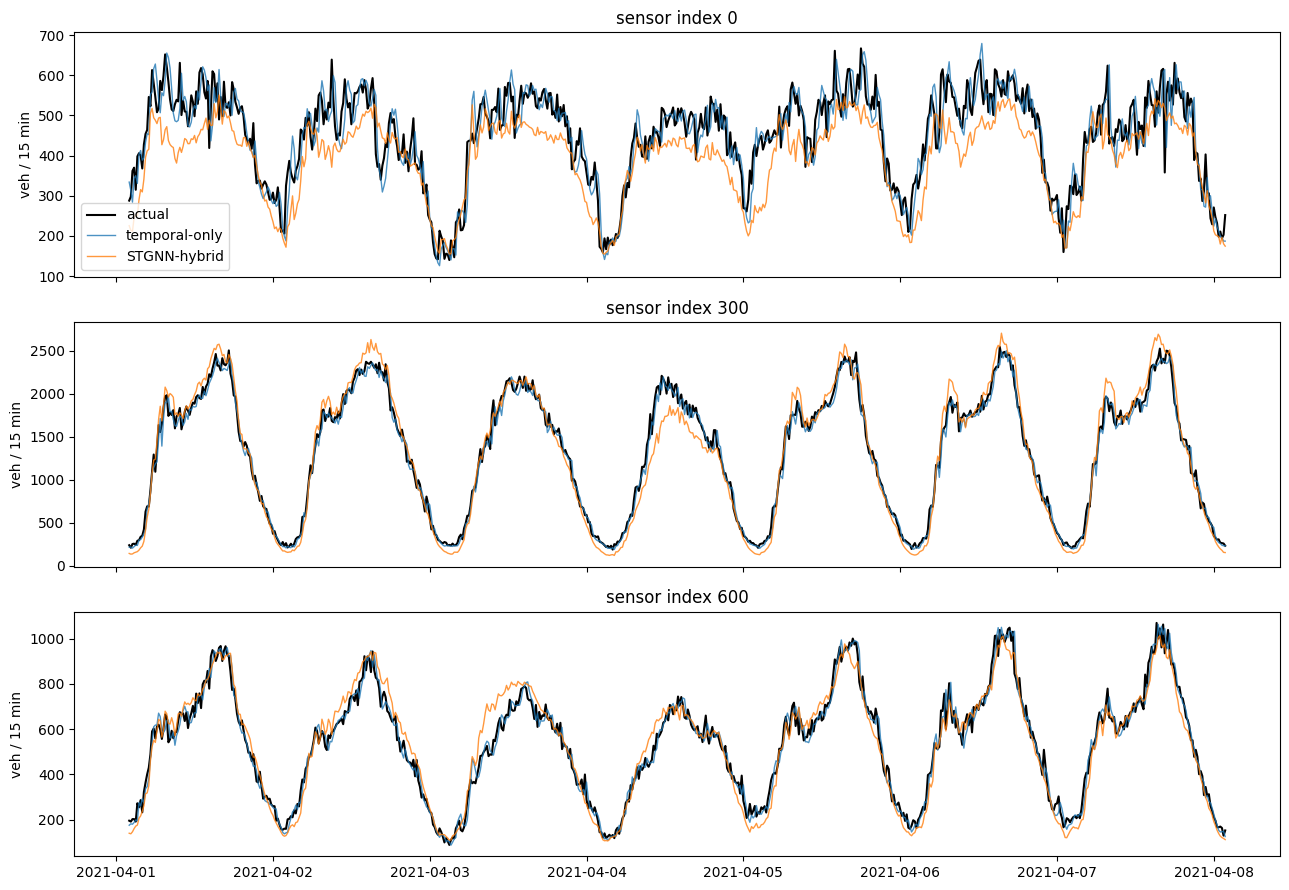

In [25]:
test_times = splits['test'].times
n_week = 7 * 96
actual = data_np[split_masks['test']]
pred_idx = np.arange(n_week)
t_axis = test_times[HIST:HIST + n_week]

best_graph = min(['fixed', 'adaptive', 'hybrid'], key=lambda k: runs[k]['val']['MAE'])
print('best graph model by validation MAE:', best_graph)
fig, axs = plt.subplots(3, 1, figsize=(13, 9), sharex=True)
for ax, s in zip(axs, [0, 300, 600]):
    ax.plot(t_axis, actual[HIST:HIST + n_week, s], 'k', lw=1.5, label='actual')
    ax.plot(t_axis, runs['none']['test']['pred_h1'][pred_idx, s], lw=1, alpha=.8, label='temporal-only')
    ax.plot(t_axis, runs[best_graph]['test']['pred_h1'][pred_idx, s], lw=1, alpha=.8, label=f'STGNN-{best_graph}')
    ax.set_title(f'sensor index {s}')
    ax.set_ylabel('veh / 15 min')
axs[0].legend()
plt.tight_layout()
plt.show()

top-5 learned edges that are also physical 1-hop edges : 6.3%
top-5 learned edges within 2 hops in the physical graph: 15.9%
physical 1-hop density (chance level): 3.38%
mean distance (km): learned top-5 23.54 | physical edges 2.28 | random pairs 27.24


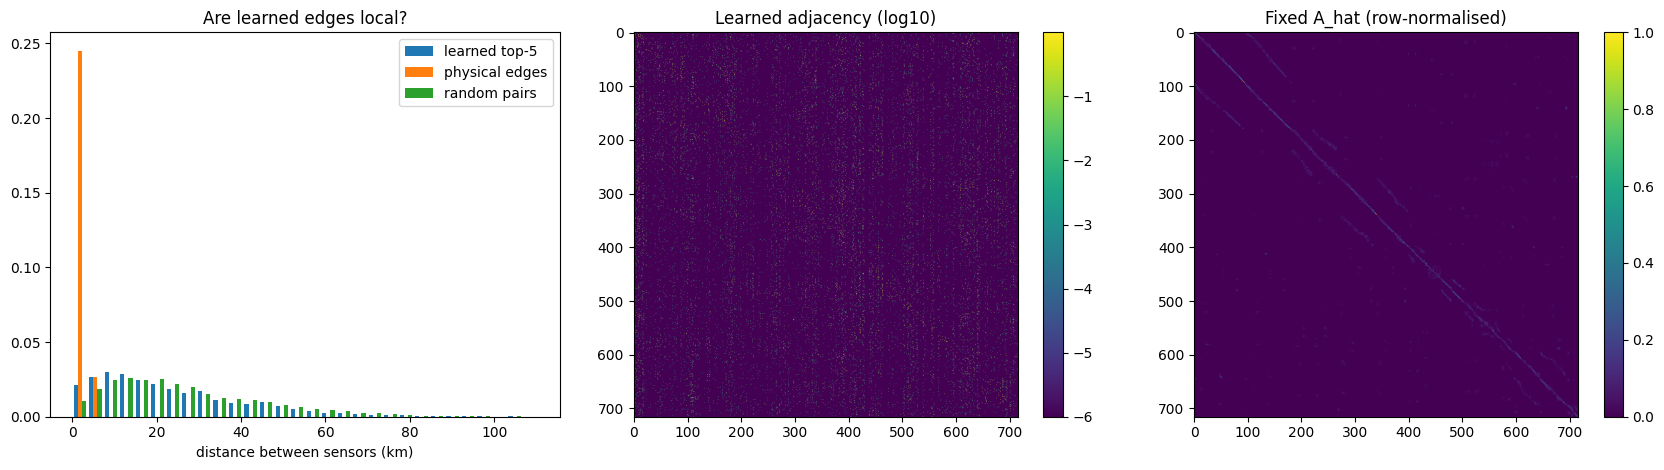

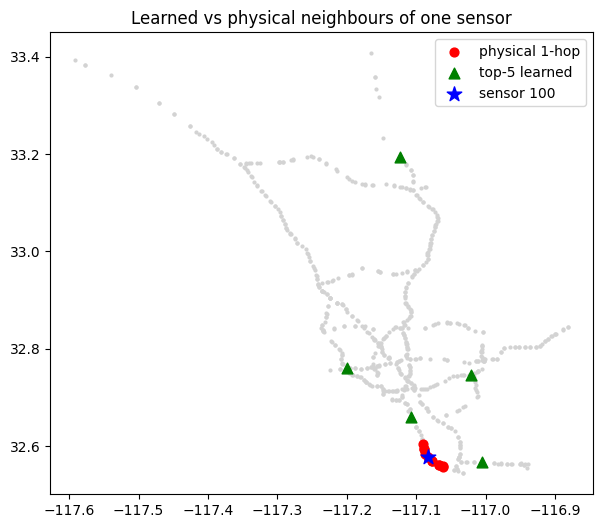

In [26]:
A_learn = models['adaptive'].adaptive_adj().detach().cpu().numpy()
np.fill_diagonal(A_learn, 0)
TOPN = 5
top_learn = np.argsort(-A_learn, axis=1)[:, :TOPN]

phys_1hop = Bin > 0
phys_2hop = (Bin @ Bin + Bin) > 0
np.fill_diagonal(phys_2hop, False)
rows_ = np.repeat(np.arange(716), TOPN); cols_ = top_learn.ravel()
print(f'top-{TOPN} learned edges that are also physical 1-hop edges : {phys_1hop[rows_, cols_].mean()*100:.1f}%')
print(f'top-{TOPN} learned edges within 2 hops in the physical graph: {phys_2hop[rows_, cols_].mean()*100:.1f}%')
print(f'physical 1-hop density (chance level): {phys_1hop.mean()*100:.2f}%')

def haversine(lat1, lng1, lat2, lng2):
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dphi, dl = p2 - p1, np.radians(lng2 - lng1)
    h = np.sin(dphi / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(dl / 2) ** 2
    return 2 * 6371 * np.arcsin(np.sqrt(h))

D = haversine(lat[:, None], lng[:, None], lat[None, :], lng[None, :])

d_learn = D[rows_, cols_]
fr, fc = np.where(phys_1hop)
d_fixed = D[fr, fc]
d_random = D[np.random.randint(0, 716, 20000), np.random.randint(0, 716, 20000)]
print(f'mean distance (km): learned top-{TOPN} {d_learn.mean():.2f} | physical edges {d_fixed.mean():.2f} | random pairs {d_random.mean():.2f}')

fig, axs = plt.subplots(1, 3, figsize=(17, 4.8))
axs[0].hist([d_learn, d_fixed, d_random], bins=30, density=True, label=['learned top-5', 'physical edges', 'random pairs'])
axs[0].set_xlabel('distance between sensors (km)'); axs[0].legend(); axs[0].set_title('Are learned edges local?')
im = axs[1].imshow(np.log10(A_learn + 1e-6), cmap='viridis')
axs[1].set_title('Learned adjacency (log10)')
plt.colorbar(im, ax=axs[1])

im = axs[2].imshow(A_hat_fixed.cpu().numpy(), cmap='viridis')
axs[2].set_title('Fixed A_hat (row-normalised)')
plt.colorbar(im, ax=axs[2])
plt.tight_layout()
plt.show()

i = 100
plt.figure(figsize=(7, 6))
plt.scatter(lng, lat, s=4, c='lightgrey')
plt.scatter(lng[np.where(phys_1hop[i])[0]], lat[np.where(phys_1hop[i])[0]], s=40, c='red', label='physical 1-hop')
plt.scatter(lng[top_learn[i]], lat[top_learn[i]], s=60, c='green', marker='^', label='top-5 learned')
plt.scatter(lng[i], lat[i], s=120, c='blue', marker='*', label=f'sensor {i}')
plt.legend()
plt.title('Learned vs physical neighbours of one sensor')
plt.show()

In [27]:
print('Seed:', CFG['seed'])
print('Hyperparameters:', CFG)
print('Python:', platform.python_version(), '| PyTorch:', torch.__version__)
print('CPU:', platform.processor() or platform.machine(), '| cores:', os.cpu_count())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))
try:
    print(subprocess.run(['free', '-h'], capture_output=True, text=True).stdout)
except Exception: pass
print(results.to_string(index=False))

Seed: 42
Hyperparameters: {'hist': 8, 'horizon': 4, 'hidden': 32, 'emb_dim': 10, 'topk': 20, 'epochs': 30, 'batch': 64, 'lr': 0.001, 'patience': 6, 'seed': 42}
Python: 3.13.16 | PyTorch: 2.14.1+cu130
CPU: x86_64 | cores: 2
GPU: Tesla T4
               total        used        free      shared  buff/cache   available
Mem:            12Gi       4.0Gi       155Mi        16Mi       8.9Gi       8.7Gi
Swap:             0B          0B          0B

        Model Adjacency  Val MAE  Val RMSE  Test MAE  Test RMSE  Training time (s)
Temporal-only      None    56.29     90.30     64.85     101.78              571.6
        STGNN     Fixed   124.14    200.59    140.14     218.94              611.1
        STGNN  Adaptive    73.44    123.74     90.60     141.53              618.3
        STGNN    Hybrid    68.47    115.98     83.17     130.40              644.4
